In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Konfigurasi Tampilan Visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# --- KONEKSI POSTGRESQL ---
DB_USER = 'postgres'
DB_PASS = 'postgres'
DB_HOST = 'localhost'
DB_PORT = '5432'
DB_NAME = 'olist_db'

connection_string = f'postgresql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}'
engine = create_engine(connection_string)
print("Koneksi ke PostgreSQL berhasil!")

Koneksi ke PostgreSQL berhasil!


In [3]:
query_rfm_raw = """
SELECT 
    c.customer_unique_id,
    o.order_id,
    o.order_purchase_timestamp::timestamp AS purchase_date,
    i.price + i.freight_value AS total_order_cost
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered';
"""

df_raw = pd.read_sql_query(query_rfm_raw, engine)
df_raw['purchase_date'] = pd.to_datetime(df_raw['purchase_date'])
df_raw.head()

,customer_unique_id,order_id,purchase_date,total_order_cost
0,871766c5855e863f6eccc05f988b23cb,00010242fe8c5a6d1ba2dd792cb16214,2017-09-13 08:59:02,72.19
1,eb28e67c4c0b83846050ddfb8a35d051,00018f77f2f0320c557190d7a144bdd3,2017-04-26 10:53:06,259.83
2,3818d81c6709e39d06b2738a8d3a2474,000229ec398224ef6ca0657da4fc703e,2018-01-14 14:33:31,216.87
3,af861d436cfc08b2c2ddefd0ba074622,00024acbcdf0a6daa1e931b038114c75,2018-08-08 10:00:35,25.78
4,64b576fb70d441e8f1b2d7d446e483c5,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04 13:57:51,218.04


In [4]:
# Tentukan snapshot date (1 hari setelah tanggal transaksi terakhir di dataset)
snapshot_date = df_raw['purchase_date'].max() + pd.Timedelta(days=1)

# Agregasi RFM per pelanggan
rfm = df_raw.groupby('customer_unique_id').agg({
    'purchase_date': lambda x: (snapshot_date - x.max()).days, # Recency
    'order_id': 'nunique',                                     # Frequency
    'total_order_cost': 'sum'                                  # Monetary
}).reset_index()

rfm.columns = ['customer_unique_id', 'Recency', 'Frequency', 'Monetary']

# Skor Kuartil (1-4)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1])
rfm['F_Score'] = pd.Series(np.where(rfm['Frequency'] > 1, 2, 1)) # Karena mayoritas beli 1x
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=[1, 2, 3, 4])

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,3
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,3,1,1
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4


In [5]:
def segment_customer(df):
    if df['R_Score'] == 4 and df['F_Score'] == 2:
        return 'Champions / Super Loyal'
    elif df['R_Score'] >= 3:
        return 'Recent / Active Customers'
    elif df['R_Score'] == 2:
        return 'At Risk / Need Attention'
    else:
        return 'Hibernating / Churned'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

# Tampilkan Distribusi Segmen Pelanggan
segment_counts = rfm['Segment'].value_counts().reset_index()
segment_counts.columns = ['Segment', 'Total_Customers']
segment_counts

,Segment,Total_Customers
0,Recent / Active Customers,46064
1,Hibernating / Churned,23311
2,At Risk / Need Attention,23200
3,Champions / Super Loyal,783


#Cohort Analysis & Heatmap

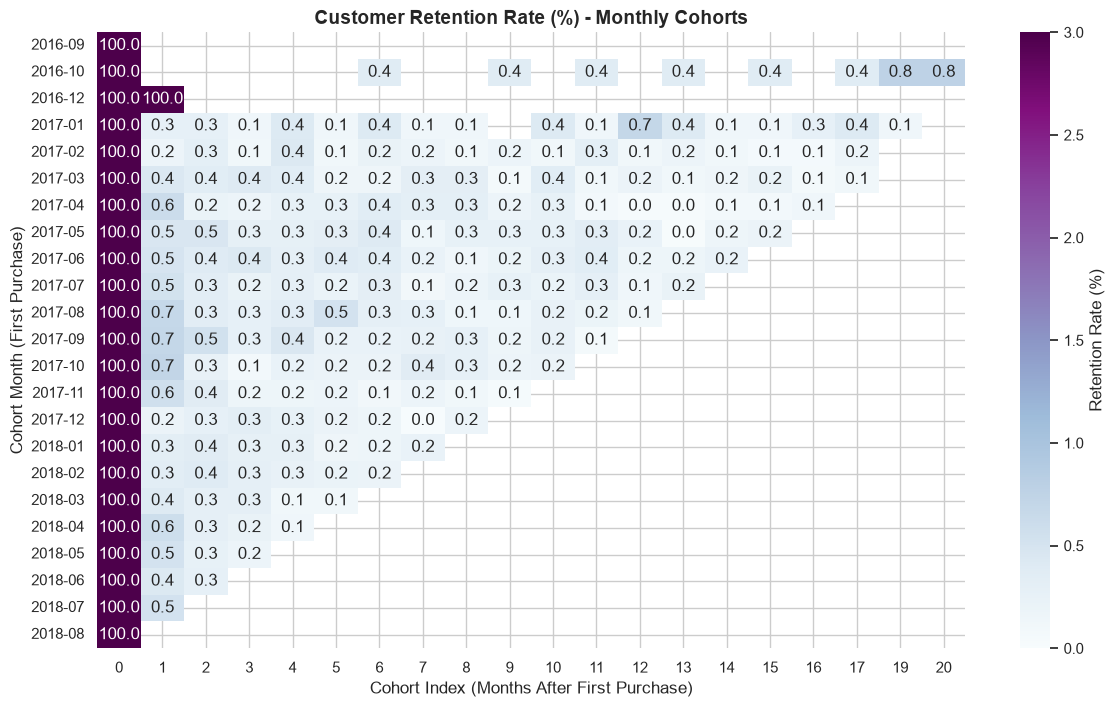

In [6]:
# 1. Tentukan Cohort Month (Bulan Transaksi Pertama Tiap Pelanggan)
df_raw['order_month'] = df_raw['purchase_date'].dt.to_period('M')
df_raw['cohort_month'] = df_raw.groupby('customer_unique_id')['purchase_date'].transform('min').dt.to_period('M')

# 2. Hitung Selisih Bulan (Cohort Index)
def get_month_int(df, column):
    year = df[column].dt.year
    month = df[column].dt.month
    return year, month

order_year, order_month = get_month_int(df_raw, 'order_month')
cohort_year, cohort_month = get_month_int(df_raw, 'cohort_month')

years_diff = order_year - cohort_year
months_diff = order_month - cohort_month

df_raw['cohort_index'] = years_diff * 12 + months_diff

# 3. Buat Tabel Pivot Cohort (Jumlah Pelanggan Unik)
cohort_data = df_raw.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()
cohort_counts = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

# 4. Hitung Persentase Retention Rate
cohort_sizes = cohort_counts.iloc[:, 0]
retention = cohort_counts.divide(cohort_sizes, axis=0) * 100

# 5. Visualisasi Heatmap Retention Rate
plt.figure(figsize=(14, 8))
plt.title('Customer Retention Rate (%) - Monthly Cohorts', fontsize=14, fontweight='bold')
sns.heatmap(
    retention, 
    annot=True, 
    fmt='.1f', 
    cmap='BuPu', 
    vmin=0.0, 
    vmax=3.0, # Disesuaikan karena retention rate e-commerce umum cenderung di bawah 3%
    cbar_kws={'label': 'Retention Rate (%)'}
)
plt.ylabel('Cohort Month (First Purchase)')
plt.xlabel('Cohort Index (Months After First Purchase)')
plt.show()

In [8]:
import os

# 1. Tarik Data Tren Penjualan Bulanan dari PostgreSQL
query_monthly = """
SELECT 
    TO_CHAR(o.order_purchase_timestamp::timestamp, 'YYYY-MM') AS order_month,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(i.price)::numeric, 2) AS monthly_revenue
FROM orders o
JOIN order_items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY order_month
ORDER BY order_month;
"""
df_monthly = pd.read_sql_query(query_monthly, engine)

# 2. Tarik Data Kategori Produk Teratas dari PostgreSQL
query_top_categories = """
SELECT 
    COALESCE(p.product_category_name_english, 'Unknown') AS category,
    COUNT(DISTINCT i.order_id) AS total_orders_sold,
    COUNT(i.product_id) AS total_items_sold,
    ROUND(SUM(i.price)::numeric, 2) AS total_revenue
FROM order_items i
JOIN products p ON i.product_id = p.product_id
JOIN orders o ON i.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY total_revenue DESC
LIMIT 10;
"""
df_top_categories = pd.read_sql_query(query_top_categories, engine)

# 3. Tarik Data Dampak Keterlambatan Pengiriman pada Review dari PostgreSQL
query_review_impact = """
SELECT 
    CASE 
        WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 'Terlambat (Late)'
        ELSE 'Tepat Waktu (On-Time)'
    END AS delivery_status,
    COUNT(r.review_id) AS total_reviews,
    ROUND(AVG(r.review_score)::numeric, 2) AS avg_review_score
FROM orders o
JOIN order_reviews r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY delivery_status;
"""
df_review_impact = pd.read_sql_query(query_review_impact, engine)

# --- PROSES EKSPOR KE CSV ---
output_dir = '../data/processed/'
os.makedirs(output_dir, exist_ok=True)

rfm.to_csv(os.path.join(output_dir, 'rfm_segmentation.csv'), index=False)
df_monthly.to_csv(os.path.join(output_dir, 'monthly_sales.csv'), index=False)
df_top_categories.to_csv(os.path.join(output_dir, 'top_categories.csv'), index=False)
df_review_impact.to_csv(os.path.join(output_dir, 'review_impact.csv'), index=False)

print("Semua 4 file CSV berhasil diekspor ke folder data/processed!")

Semua 4 file CSV berhasil diekspor ke folder data/processed!
